# Is there a dialect map in the encoder's latent space?

Embed every clip with a (frozen) speech encoder, look at the latent space and see whether speakers group by
dialect without being told the labels.

A clip embedding mixes much more than dialect: the speaker's voice, gender, the sentence, the microphone and
room. Dialect is a property of the **speaker**, so most of the analysis works on speaker embeddings (the
frame-weighted mean over all of a speaker's clips), which averages out the sentence and much of the noise.
The labels (dialect region, canton, municipality) are only used to *colour* and *score* what comes out:

1. **Embeddings**: precomputed Whisper hidden states, or compute them now with any Whisper checkpoint.
2. **Which layer?** How well dialect (and, as a nuisance reference, gender) can be read from each layer on unseen speakers.
3. **Clips**: what the raw clip space is organised by.
4. **Speakers**: PCA / UMAP of speaker embeddings, before and after removing gender.
5. **Clusters without labels**: k-means / Ward on speakers, compared with the dialect regions.
6. **A dialect subspace**: LDA fitted on half of the speakers, applied to the other half.
7. **Geography**: clusters and principal components on the map, embedding vs geographic distance.

In [1]:
from pathlib import Path

import geopandas as gpd
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score, normalized_mutual_info_score,
                             silhouette_score)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm, trange

from maloney.data.meta import read_geo_table, read_h5_index, read_split
from maloney.embeddings import EmbeddingStore

try:
    from umap import UMAP  # optional (uv pip install umap-learn); t-SNE otherwise
except ImportError:
    UMAP = None

ROOT = Path(rootutils.find_root(indicator=".project-root"))
DATA_DIR = ROOT / "data/stt4sg-350_v2-1"
SEED = 0

# Clip metadata (speaker, dialect region, zip code): every tsv found here, so all speakers that have both
# metadata and embeddings are used. The official tsvs (train_all/valid/test) list every clip of the release;
# the custom splits are subsets of them.
TSVS = [DATA_DIR / f"{name}.tsv" for name in ("train_all", "valid", "test")] + sorted(DATA_DIR.glob("splits/*/*.tsv"))

# None: the precomputed embeddings below (all clips). A Whisper checkpoint (e.g. "openai/whisper-small"):
# embed CLIPS_PER_SPEAKER random clips of every speaker now (needs their audio in audio_16k.h5; cached in CACHE_DIR).
MODEL = None
PRECOMPUTED = DATA_DIR / "embeddings/openai__whisper-large-v3.h5"
CLIPS_PER_SPEAKER = 40
CACHE_DIR = DATA_DIR / "embeddings/notebook"

## 1. Embeddings

The speakers are those with metadata in `TSVS` and embeddings in the `.h5` file (or audio, with `MODEL`).
Embeddings come from the cluster's `scripts/extract_whisper_embeddings.py`, which covers the whole release, so
the tsvs decide how many speakers there are: copy `train_all.tsv`, `valid.tsv` and `test.tsv` from the cluster
for all of them, and rebuild `zip_municipality.csv` for their locations
(`uv run --extra geo python scripts/build_zip_geo.py data/stt4sg-350_v2-1`).

`load_layer(layer)` gives the clip embeddings of one layer `[n_clips, dim]`, row-aligned with `meta`; layers are
read one at a time (all 8 layers of whisper-large-v3 for the whole release would take ~10 GB).

In [2]:
meta = pd.concat([pd.read_csv(tsv, sep="	", quoting=3, dtype={"zipcode": str, "client_id": str})
                  for tsv in TSVS if tsv.is_file()]).drop_duplicates("path")
meta = meta.join(read_geo_table(DATA_DIR / "zip_municipality.csv"), on="zipcode")

if MODEL is None:
    store = EmbeddingStore(PRECOMPUTED)
    meta = meta[meta.path.isin(store.row.index)].reset_index(drop=True)
    rows = store.rows(meta.path)
    meta["frames"] = store.frames[rows]
    LAYERS = store.layers

    def load_layer(layer):
        with h5py.File(PRECOMPUTED, "r") as f:
            return f[f"layer_{layer:02d}"][:][rows].astype(np.float32)

    print(store)
else:
    index, _ = read_h5_index(DATA_DIR / "audio_16k.h5")
    meta = meta[meta.path.isin(index.index)]
    meta = meta.sample(frac=1, random_state=SEED).groupby("client_id").head(CLIPS_PER_SPEAKER).reset_index(drop=True)
    cache = CACHE_DIR / f"{MODEL.replace('/', '__')}_{CLIPS_PER_SPEAKER}.npz"
    if cache.is_file():
        saved = np.load(cache, allow_pickle=True)
        assert (saved["path"] == meta.path.to_numpy()).all(), f"{cache} holds other clips; delete it"
        emb, meta["frames"], layers = saved["emb"], saved["frames"], saved["layers"].tolist()
    else:
        import torch
        from maloney.embeddings.whisper import WhisperEmbedder

        device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
        embedder = WhisperEmbedder(MODEL, device=device)
        loc = index.loc[meta.path]
        embs, frames = [], []
        with h5py.File(DATA_DIR / "audio_16k.h5", "r") as f:
            for i in trange(0, len(meta), 16, desc=MODEL):
                audios = [f["audio"][o: o + n].astype(np.float32) / 32767
                          for o, n in zip(loc.offset[i: i + 16], loc.length[i: i + 16])]
                e, fr = embedder.embed(audios)
                embs.append(e)
                frames.append(fr)
        emb, meta["frames"], layers = np.concatenate(embs), np.concatenate(frames), embedder.layers
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        np.savez(cache, emb=emb, frames=meta.frames.to_numpy(), layers=layers, path=meta.path.to_numpy())
    LAYERS = list(layers)

    def load_layer(layer):
        return emb[:, LAYERS.index(layer)]

# One row per speaker, sorted by client_id (the order of every speaker-level array below).
speakers = meta.groupby("client_id", sort=True).agg(
    dialect_region=("dialect_region", "first"), canton=("canton", "first"), gender=("gender", "first"),
    age=("age", "first"), municipality=("municipality", "first"), E=("muni_E", "first"), N=("muni_N", "first"),
    clips=("path", "size"), minutes=("duration", lambda d: d.sum() / 60))
REGIONS = sorted(speakers.dialect_region.unique())
REGION_COLORS = dict(zip(REGIONS, plt.get_cmap("tab10").colors))

print(f"{len(meta)} clips, {len(speakers)} speakers, layers {LAYERS}")
speakers.groupby("dialect_region").agg(
    speakers=("canton", "size"), cantons=("canton", lambda c: ", ".join(sorted(set(c)))),
    female=("gender", lambda g: (g == "female").mean()), minutes_per_speaker=("minutes", "mean")).round(2)

EmbeddingStore(openai/whisper-large-v3, 247527 clips, layers [4, 8, 12, 16, 20, 24, 28, 32], dim 1280)
47822 clips, 97 speakers, layers [4, 8, 12, 16, 20, 24, 28, 32]


,speakers,cantons,female,minutes_per_speaker
dialect_region,,,,
Basel,15,"BL, BS",0.53,39.24
Bern,15,"AG, BE, SO",0.27,37.48
Graubünden,14,"GR, TI",0.71,40.09
Innerschweiz,14,"AG, GL, LU, OW, UR, ZG",0.71,39.28
Ostschweiz,13,"SG, SH, TG",0.38,41.27
Wallis,11,VS,0.82,57.30
Zürich,15,"AG, ZH",0.27,40.86


Helpers. Two details matter for distances in Whisper's space:

- **Standardise** every dimension first: a handful of Whisper dimensions have magnitudes far above the rest
  and would otherwise dominate cosine/Euclidean distances (and PCA).
- **Gender** is the strongest speaker property in voice embeddings. `prepare(..., gender=...)` removes the mean
  difference between female and male speakers. Mind that this also removes dialect differences if a region's
  speakers are mostly of one gender (see `female` above).

In [3]:
def pool(X, groups, weights=None):
    """Weighted mean of the rows of X per group, groups in sorted order (speaker embeddings: frame-weighted)."""
    keys, codes = np.unique(np.asarray(groups), return_inverse=True)
    w = np.ones(len(X)) if weights is None else np.asarray(weights, dtype=float)
    sums = np.zeros((len(keys), X.shape[1]))
    np.add.at(sums, codes, X * w[:, None])
    return sums / np.bincount(codes, w)[:, None]


def prepare(S, gender=None):
    """Standardised speaker embeddings, optionally centred per gender."""
    Z = StandardScaler().fit_transform(S)
    if gender is not None:
        gender = np.asarray(gender)
        for g in np.unique(gender):
            Z[gender == g] -= Z[gender == g].mean(0)
    return Z


def decode(X, meta, label, clips_per_speaker=60):
    """Balanced accuracy of predicting `label` for unseen speakers (5-fold CV over speakers, logistic
    regression on clips), per clip and per speaker (mean probability over the speaker's clips)."""
    sub = meta.sample(frac=1, random_state=SEED).groupby("client_id").head(clips_per_speaker)
    y, groups = sub[label].to_numpy(), sub.client_id.to_numpy()
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
    proba = cross_val_predict(clf, X[sub.index], y, groups=groups, cv=cv, method="predict_proba")
    proba = pd.DataFrame(proba, columns=np.unique(y))
    per_speaker = proba.groupby(groups).mean()
    truth = sub.groupby("client_id")[label].first().loc[per_speaker.index]
    return {"clip": balanced_accuracy_score(y, proba.idxmax(axis=1)),
            "speaker": balanced_accuracy_score(truth, per_speaker.idxmax(axis=1))}


def geo_correlation(Z, speakers, same_gender=True):
    """Spearman correlation of embedding (cosine) and geographic distance over speaker pairs; with
    `same_gender` only pairs of the same gender, so gender cannot create or hide the correlation."""
    ok = speakers[["E", "N"]].notna().all(axis=1).to_numpy()
    D, G = squareform(pdist(Z[ok], "cosine")), squareform(pdist(speakers.loc[ok, ["E", "N"]].to_numpy()))
    i, j = np.triu_indices(ok.sum(), 1)
    keep = speakers.gender.to_numpy()[ok][i] == speakers.gender.to_numpy()[ok][j] if same_gender else slice(None)
    return spearmanr(D[i, j][keep], G[i, j][keep]).statistic


def embed_2d(Z, neighbours=15):
    """2-d map of the rows of Z: UMAP if installed, else t-SNE (on the first 50 principal components)."""
    Z = PCA(min(50, *Z.shape), random_state=SEED).fit_transform(Z)
    if UMAP is not None:
        return UMAP(n_neighbors=neighbours, metric="cosine", random_state=SEED).fit_transform(Z)
    return TSNE(perplexity=neighbours, metric="cosine", init="pca", random_state=SEED).fit_transform(Z)


MAP_2D = "UMAP" if UMAP is not None else "t-SNE"
GENDER_MARKERS = {"female": "o", "male": "^"}


def plot_speakers(ax, xy, speakers, title, colors=None, labels=True):
    """Speakers as points (colour: dialect region unless given, marker: gender), labelled with their canton."""
    colors = np.array([REGION_COLORS[r] for r in speakers.dialect_region]) if colors is None else np.asarray(colors)
    for gender, marker in GENDER_MARKERS.items():
        m = (speakers.gender == gender).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], c=colors[m], marker=marker, s=60, edgecolor="black", linewidth=0.4)
    if labels:
        for (x, y), canton in zip(xy, speakers.canton):
            ax.annotate(canton, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points", alpha=0.7)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def legend(fig, regions=True, genders=True):
    handles = [Line2D([], [], marker="o", linestyle="", markerfacecolor=c, markeredgecolor="black", label=r)
               for r, c in REGION_COLORS.items()] if regions else []
    handles += [Line2D([], [], marker=m, linestyle="", color="grey", label=g)
                for g, m in GENDER_MARKERS.items()] if genders else []
    fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)

## 2. Which layer carries dialect?

Per layer: **decoding** dialect region / gender of unseen speakers (balanced accuracy; chance is 1/7 for dialect,
1/2 for gender), the **silhouette** of the dialect regions among speaker embeddings (> 0: regions are compact and
apart, ≈ 0: no structure) and the **geo** correlation between embedding and geographic distance of same-gender
speaker pairs. Decoding is supervised, the other two are not: a layer can carry dialect that a linear probe
finds while it is not the main axis of variation (silhouette ≈ 0), which is what sections 4-6 explore.

In [4]:
def layer_report(load_layer, layers, meta, speakers):
    rows = []
    for layer in tqdm(layers, desc="layers"):
        X = load_layer(layer)
        Z = prepare(pool(X, meta.client_id, meta.frames), speakers.gender)
        rows.append({"layer": layer,
                     **{f"dialect_{k}": v for k, v in decode(X, meta, "dialect_region").items()},
                     **{f"gender_{k}": v for k, v in decode(X, meta, "gender").items()},
                     "silhouette": silhouette_score(Z, speakers.dialect_region, metric="cosine"),
                     "geo": geo_correlation(Z, speakers)})
    return pd.DataFrame(rows).set_index("layer")


report = layer_report(load_layer, LAYERS, meta, speakers)
LAYER = report.dialect_speaker.idxmax()
print(f"using layer {LAYER} below")
report.round(3)

layers:   0%|          | 0/8 [00:00<?, ?it/s]

using layer 24 below


,dialect_clip,dialect_speaker,gender_clip,gender_speaker,silhouette,geo
layer,,,,,,
4,0.214,0.239,0.925,0.948,-0.075,-0.012
8,0.212,0.234,0.950,0.969,-0.067,-0.018
12,0.205,0.221,0.955,0.959,-0.069,-0.018
16,0.236,0.256,0.963,0.979,-0.075,-0.008
20,0.410,0.549,0.963,0.979,-0.033,0.059
24,0.435,0.600,0.961,0.979,-0.056,0.027
28,0.381,0.519,0.959,0.979,-0.076,0.010
32,0.302,0.414,0.957,0.979,-0.054,0.070


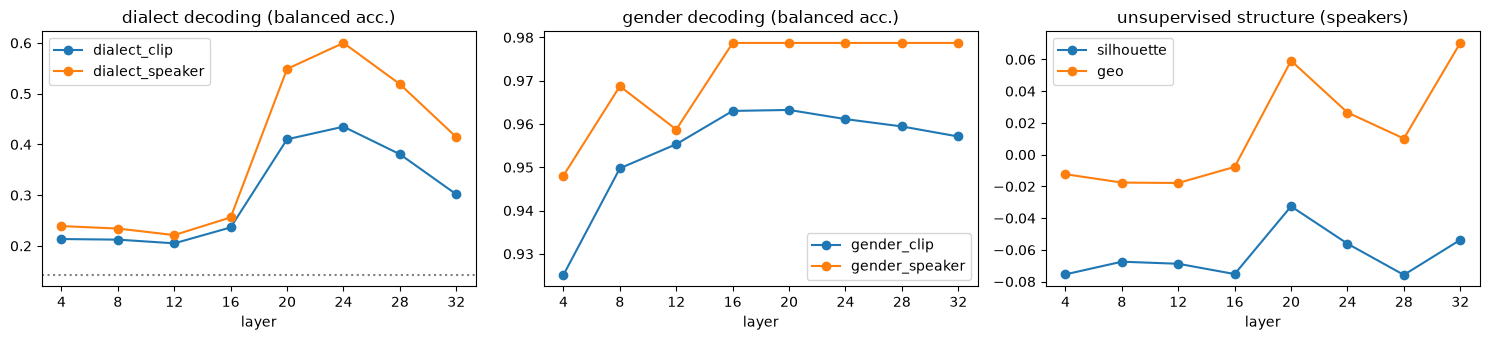

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
report[["dialect_clip", "dialect_speaker"]].plot(ax=axes[0], marker="o", title="dialect decoding (balanced acc.)")
axes[0].axhline(1 / len(REGIONS), color="grey", linestyle=":", label="chance")
report[["gender_clip", "gender_speaker"]].plot(ax=axes[1], marker="o", title="gender decoding (balanced acc.)")
report[["silhouette", "geo"]].plot(ax=axes[2], marker="o", title="unsupervised structure (speakers)")
for ax in axes:
    ax.set_xticks(report.index)
fig.tight_layout()
plt.show()

## 3. The clip space

A sample of clips from every speaker, coloured three ways. If clips mostly form one blob per speaker and split
by gender, the clip level is dominated by voice rather than dialect, and pooling per speaker is the way to go.

/Users/felix/PhD/02_Edu/maloney/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


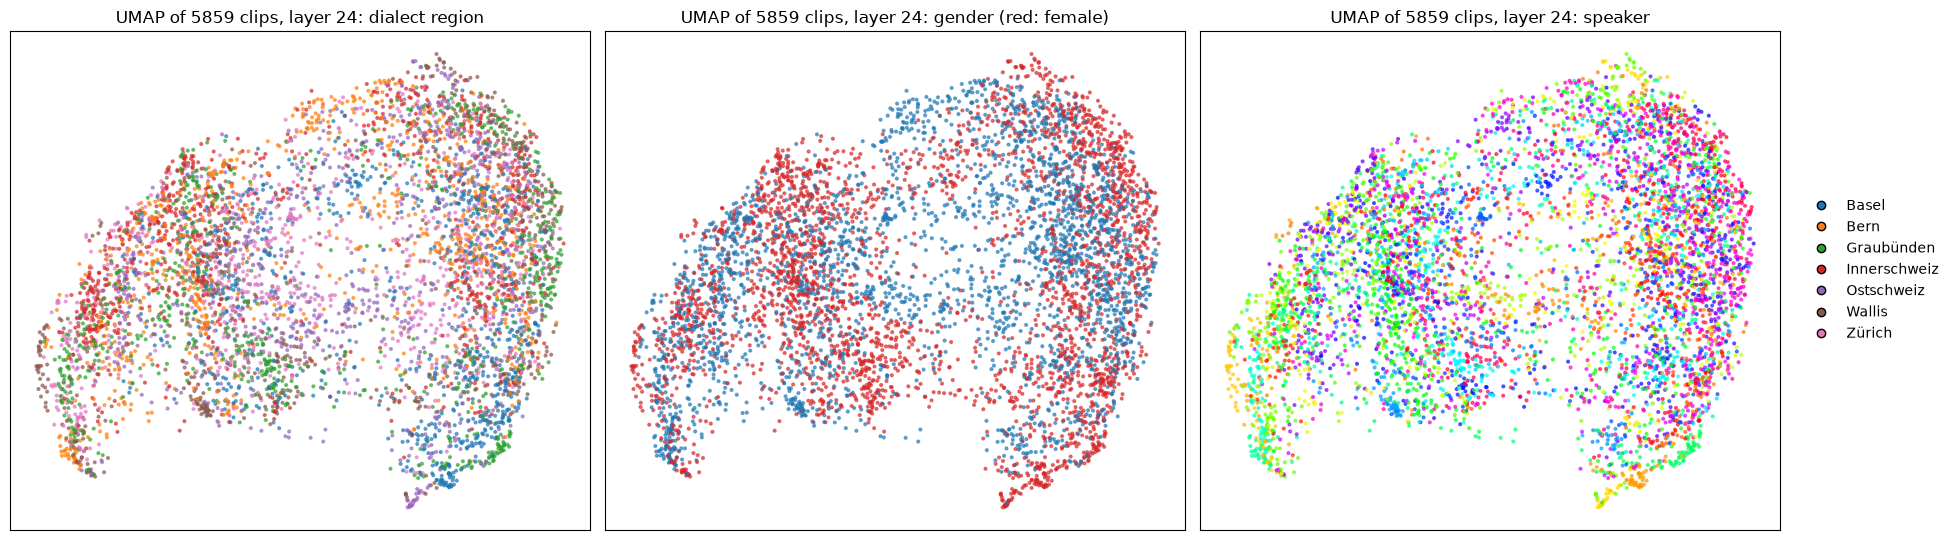

In [6]:
X = load_layer(LAYER)
# ~6000 clips in all (t-SNE gets slow beyond that)
clips = meta.sample(frac=1, random_state=SEED).groupby("client_id").head(max(5, 6000 // len(speakers)))
xy = embed_2d(StandardScaler().fit_transform(X[clips.index]), neighbours=30)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
speaker_ids = clips.client_id.astype("category").cat.codes
for ax, colors, title in [
    (axes[0], [REGION_COLORS[r] for r in clips.dialect_region], "dialect region"),
    (axes[1], np.where(clips.gender == "female", "tab:red", "tab:blue"), "gender (red: female)"),
    (axes[2], plt.get_cmap("hsv")(speaker_ids / speaker_ids.max()), "speaker"),
]:
    ax.scatter(xy[:, 0], xy[:, 1], c=colors, s=4, alpha=0.6)
    ax.set_title(f"{MAP_2D} of {len(clips)} clips, layer {LAYER}: {title}")
    ax.set_xticks([])
    ax.set_yticks([])
legend(fig, genders=False)
fig.tight_layout()
plt.show()

## 4. Speaker embeddings

One point per speaker. Top row: standardised only; bottom row: also centred per gender. Labels are cantons,
markers the gender. Look for points of one colour (region) or neighbouring cantons ending up close together.

/Users/felix/PhD/02_Edu/maloney/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/felix/PhD/02_Edu/maloney/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


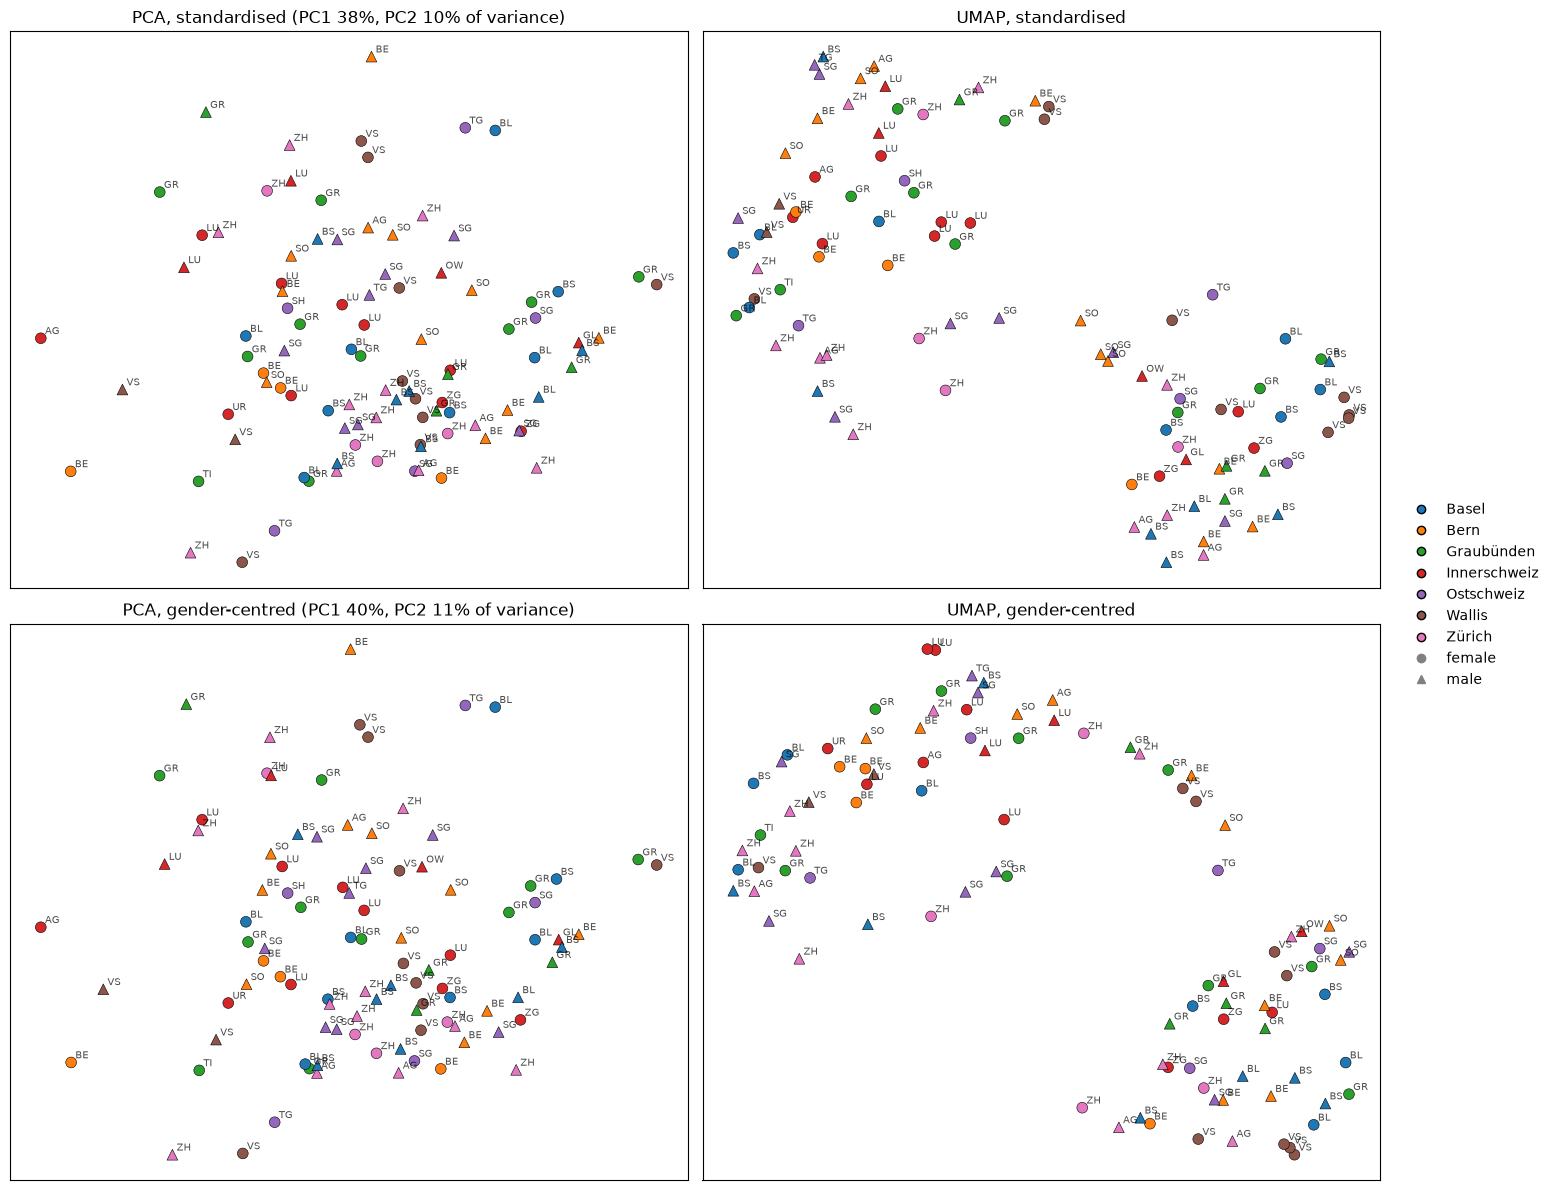

In [7]:
S = pool(X, meta.client_id, meta.frames)
Z_raw, Z = prepare(S), prepare(S, speakers.gender)  # Z (gender-centred) is used from here on

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for row, (Zs, name) in enumerate([(Z_raw, "standardised"), (Z, "gender-centred")]):
    pca = PCA(2, random_state=SEED).fit(Zs)
    var = pca.explained_variance_ratio_
    plot_speakers(axes[row, 0], pca.transform(Zs), speakers,
                  f"PCA, {name} (PC1 {var[0]:.0%}, PC2 {var[1]:.0%} of variance)")
    plot_speakers(axes[row, 1], embed_2d(Zs, neighbours=10), speakers, f"{MAP_2D}, {name}")
legend(fig)
fig.tight_layout()
plt.show()

## 5. Clusters without labels

Cluster the speakers (k-means and Ward on the first 20 principal components) for several k and compare with
the dialect regions: **ARI** / **NMI** are 0 for clusters unrelated to the regions and 1 for the regions
themselves. The silhouette (of the clusters, not the regions) says whether any k gives well separated clusters
at all.

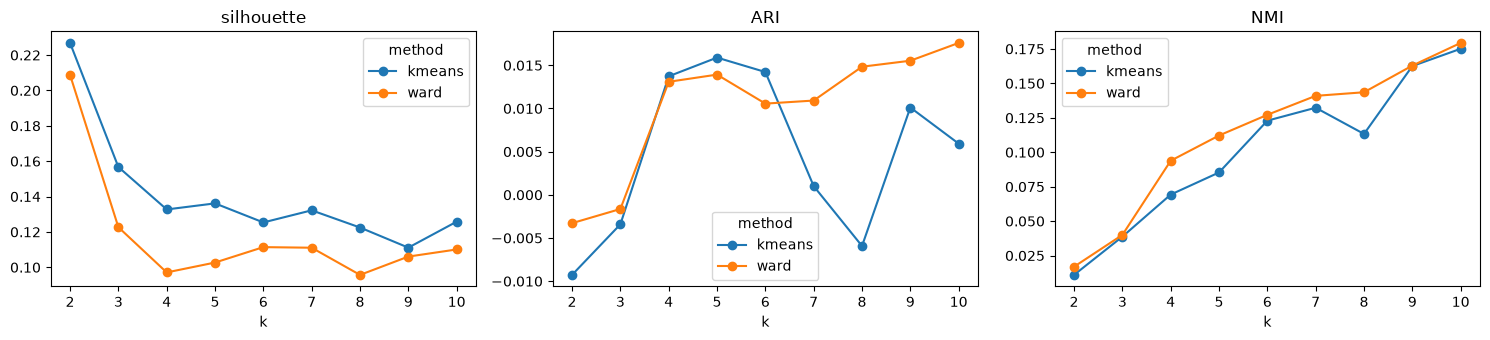

k-means with k=7: NMI 0.132, shuffled regions NMI 0.117 ± 0.022


k-means cluster (k=7),0,1,2,3,4,5,6
dialect_region,,,,,,,
Basel,4,0,5,3,1,2,0
Bern,4,1,4,0,1,3,2
Graubünden,3,2,2,1,3,2,1
Innerschweiz,1,4,3,0,1,5,0
Ostschweiz,3,0,2,0,1,6,1
Wallis,3,0,4,0,1,1,2
Zürich,2,3,5,0,0,5,0


In [8]:
Zp = PCA(min(20, len(Z) - 1), random_state=SEED).fit_transform(Z)
rows, clusterings = [], {}
for k in range(2, 11):
    for method, model in [("kmeans", KMeans(k, n_init=20, random_state=SEED)),
                          ("ward", AgglomerativeClustering(k, linkage="ward"))]:
        labels = clusterings[method, k] = model.fit_predict(Zp)
        rows.append({"k": k, "method": method, "silhouette": silhouette_score(Zp, labels),
                     "ARI": adjusted_rand_score(speakers.dialect_region, labels),
                     "NMI": normalized_mutual_info_score(speakers.dialect_region, labels)})
clustering = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, metric in zip(axes, ["silhouette", "ARI", "NMI"]):
    clustering.pivot(index="k", columns="method", values=metric).plot(ax=ax, marker="o", title=metric)
fig.tight_layout()
plt.show()

# Shuffled regions give the ARI/NMI expected by chance for this many speakers.
rng = np.random.default_rng(SEED)
k_regions = clusterings["kmeans", len(REGIONS)]
null = [normalized_mutual_info_score(rng.permutation(speakers.dialect_region), k_regions) for _ in range(1000)]
print(f"k-means with k={len(REGIONS)}: NMI {normalized_mutual_info_score(speakers.dialect_region, k_regions):.3f}, "
      f"shuffled regions NMI {np.mean(null):.3f} ± {np.std(null):.3f}")
pd.crosstab(speakers.dialect_region, k_regions, colnames=[f"k-means cluster (k={len(REGIONS)})"])

The speaker tree (Ward): leaves are cantons, coloured by dialect region. Same-coloured runs of leaves are
speakers of a region that the encoder places next to each other.

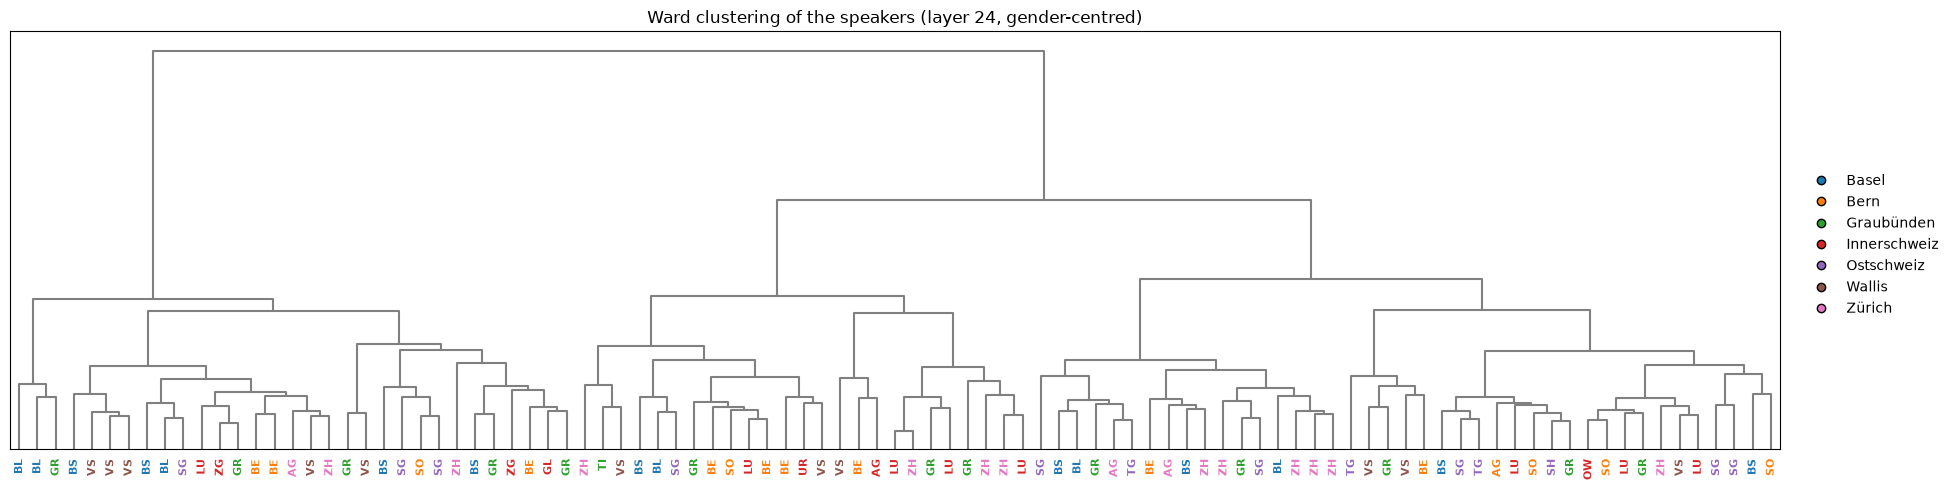

In [9]:
fig, ax = plt.subplots(figsize=(18, 5))
tree = dendrogram(linkage(Zp, "ward"), labels=speakers.canton.tolist(), ax=ax, leaf_font_size=8,
                  color_threshold=0, above_threshold_color="grey")
for tick, leaf in zip(ax.get_xticklabels(), tree["leaves"]):
    tick.set_color(REGION_COLORS[speakers.dialect_region.iloc[leaf]])
    tick.set_fontweight("bold")
ax.set_title(f"Ward clustering of the speakers (layer {LAYER}, gender-centred)")
ax.set_yticks([])
legend(fig, genders=False)
fig.tight_layout()
plt.show()

Which regions sound alike? Distance between the region centroids in the embedding space next to the
geographic distance between the regions (mean speaker location). Dialectologically, the Wallis and
Graubünden are expected to stand out, Zürich/Ostschweiz/Innerschweiz to be close.

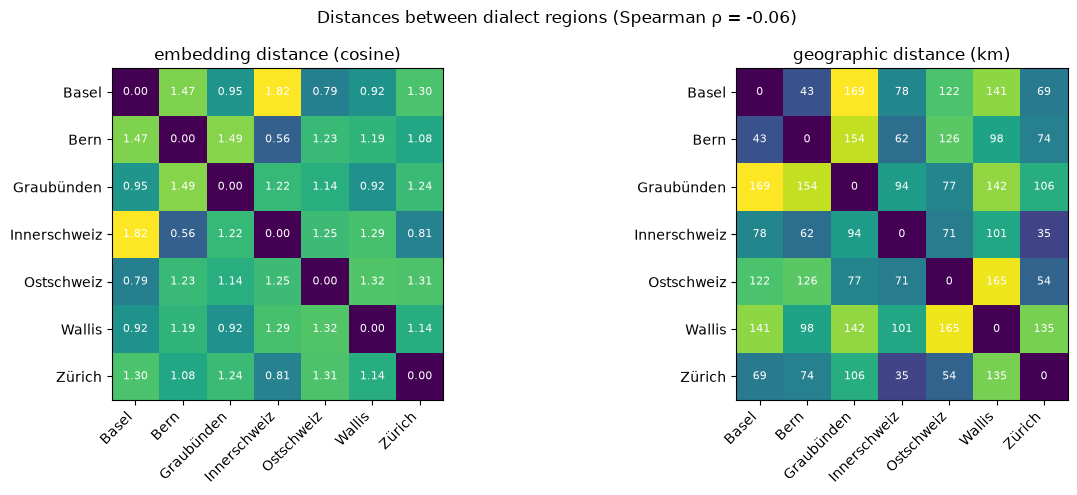

In [10]:
centroids = pd.DataFrame(Z, index=speakers.index).groupby(speakers.dialect_region).mean()
emb_dist = pd.DataFrame(squareform(pdist(centroids, "cosine")), index=REGIONS, columns=REGIONS)
geo_dist = pd.DataFrame(squareform(pdist(speakers.groupby("dialect_region")[["E", "N"]].mean())) / 1000,
                        index=REGIONS, columns=REGIONS)
i, j = np.triu_indices(len(REGIONS), 1)
rho = spearmanr(emb_dist.to_numpy()[i, j], geo_dist.to_numpy()[i, j]).statistic

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dist, title, fmt in [(axes[0], emb_dist, "embedding distance (cosine)", ".2f"),
                             (axes[1], geo_dist, "geographic distance (km)", ".0f")]:
    im = ax.imshow(dist, cmap="viridis")
    for a in range(len(REGIONS)):
        for b in range(len(REGIONS)):
            ax.text(b, a, format(dist.iat[a, b], fmt), ha="center", va="center", fontsize=8, color="white")
    ax.set_xticks(range(len(REGIONS)), REGIONS, rotation=45, ha="right")
    ax.set_yticks(range(len(REGIONS)), REGIONS)
    ax.set_title(title)
fig.suptitle(f"Distances between dialect regions (Spearman ρ = {rho:.2f})")
fig.tight_layout()
plt.show()

## 6. A dialect subspace

The unsupervised views show the *largest* directions of variation, which need not be dialect. LDA instead looks
for the directions that separate the regions. To keep it honest, it is fitted on the clips of half of the
speakers of every region and applied to the other half: if the held-out speakers (large points) still land with
their region, there is a dialect subspace that generalises to new speakers.

held-out speakers: balanced accuracy 0.32 (chance 0.14)


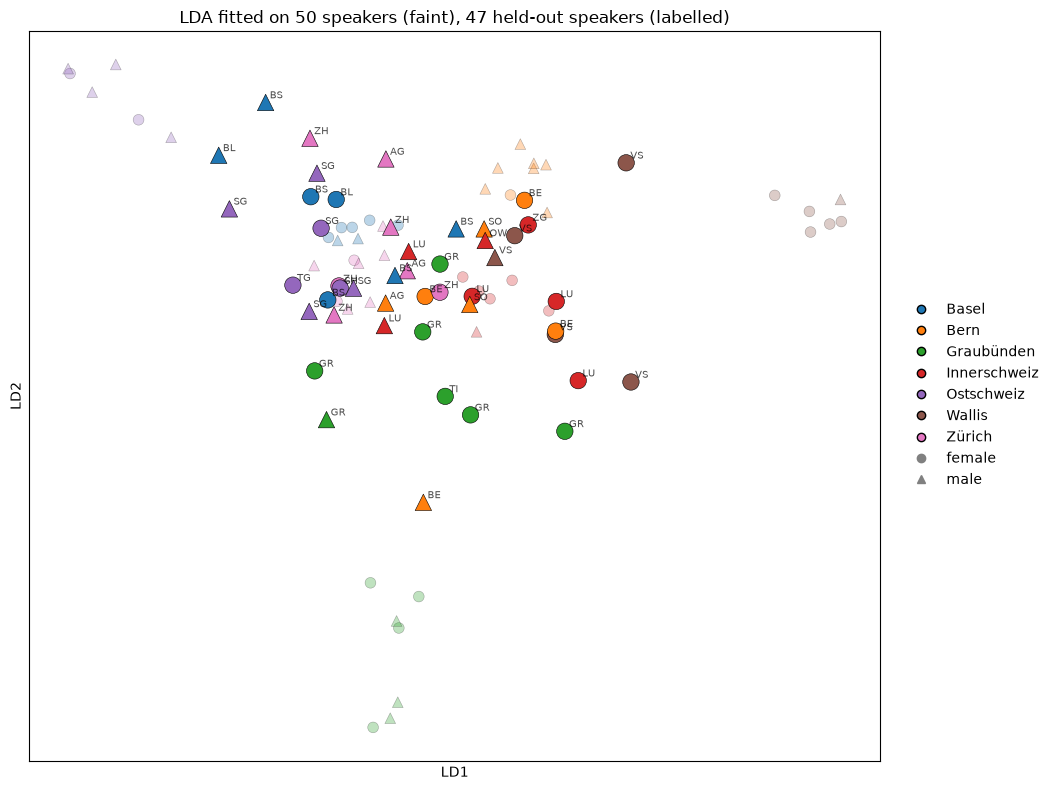

In [11]:
fit_speakers = speakers.groupby("dialect_region").sample(frac=0.5, random_state=SEED).index
fitted = speakers.index.isin(fit_speakers)
on_fit = meta.client_id.isin(fit_speakers).to_numpy()
# Centre the clips per gender (means of the fitted speakers), else LDA picks up gender wherever the regions'
# gender balance differs.
gender_mean = {g: X[on_fit & (meta.gender == g).to_numpy()].mean(0) for g in GENDER_MARKERS}
Xc = X - np.stack(meta.gender.map(gender_mean))
lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto"))
lda.fit(Xc[on_fit], meta.dialect_region[on_fit])

held_out = speakers[~fitted]
proba = pd.DataFrame(lda.predict_proba(Xc[~on_fit]), columns=lda.classes_).groupby(meta.client_id[~on_fit].to_numpy()).mean()
acc = balanced_accuracy_score(held_out.dialect_region, proba.loc[held_out.index].idxmax(axis=1))
print(f"held-out speakers: balanced accuracy {acc:.2f} (chance {1 / len(REGIONS):.2f})")

xy = lda.transform(pool(Xc, meta.client_id, meta.frames))[:, :2]  # speaker means (the projection is linear)
fig, ax = plt.subplots(figsize=(9, 8))
plot_speakers(ax, xy[fitted], speakers[fitted], "", labels=False)
for c in ax.collections[-2:]:
    c.set_alpha(0.3)
plot_speakers(ax, xy[~fitted], held_out,
              f"LDA fitted on {fitted.sum()} speakers (faint), {len(held_out)} held-out speakers (labelled)")
for c in ax.collections[-2:]:
    c.set_sizes([140])
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
legend(fig)
fig.tight_layout()
plt.show()

## 7. Geography

Speakers at their municipality (jittered by ~3 km so that speakers of the same town do not overlap): the true
regions, the label-free k-means clusters, and the first two principal components of the speaker embeddings as
colour. A smooth gradient of PC colour across the map would be dialect (or something correlated with place)
showing up without any labels.

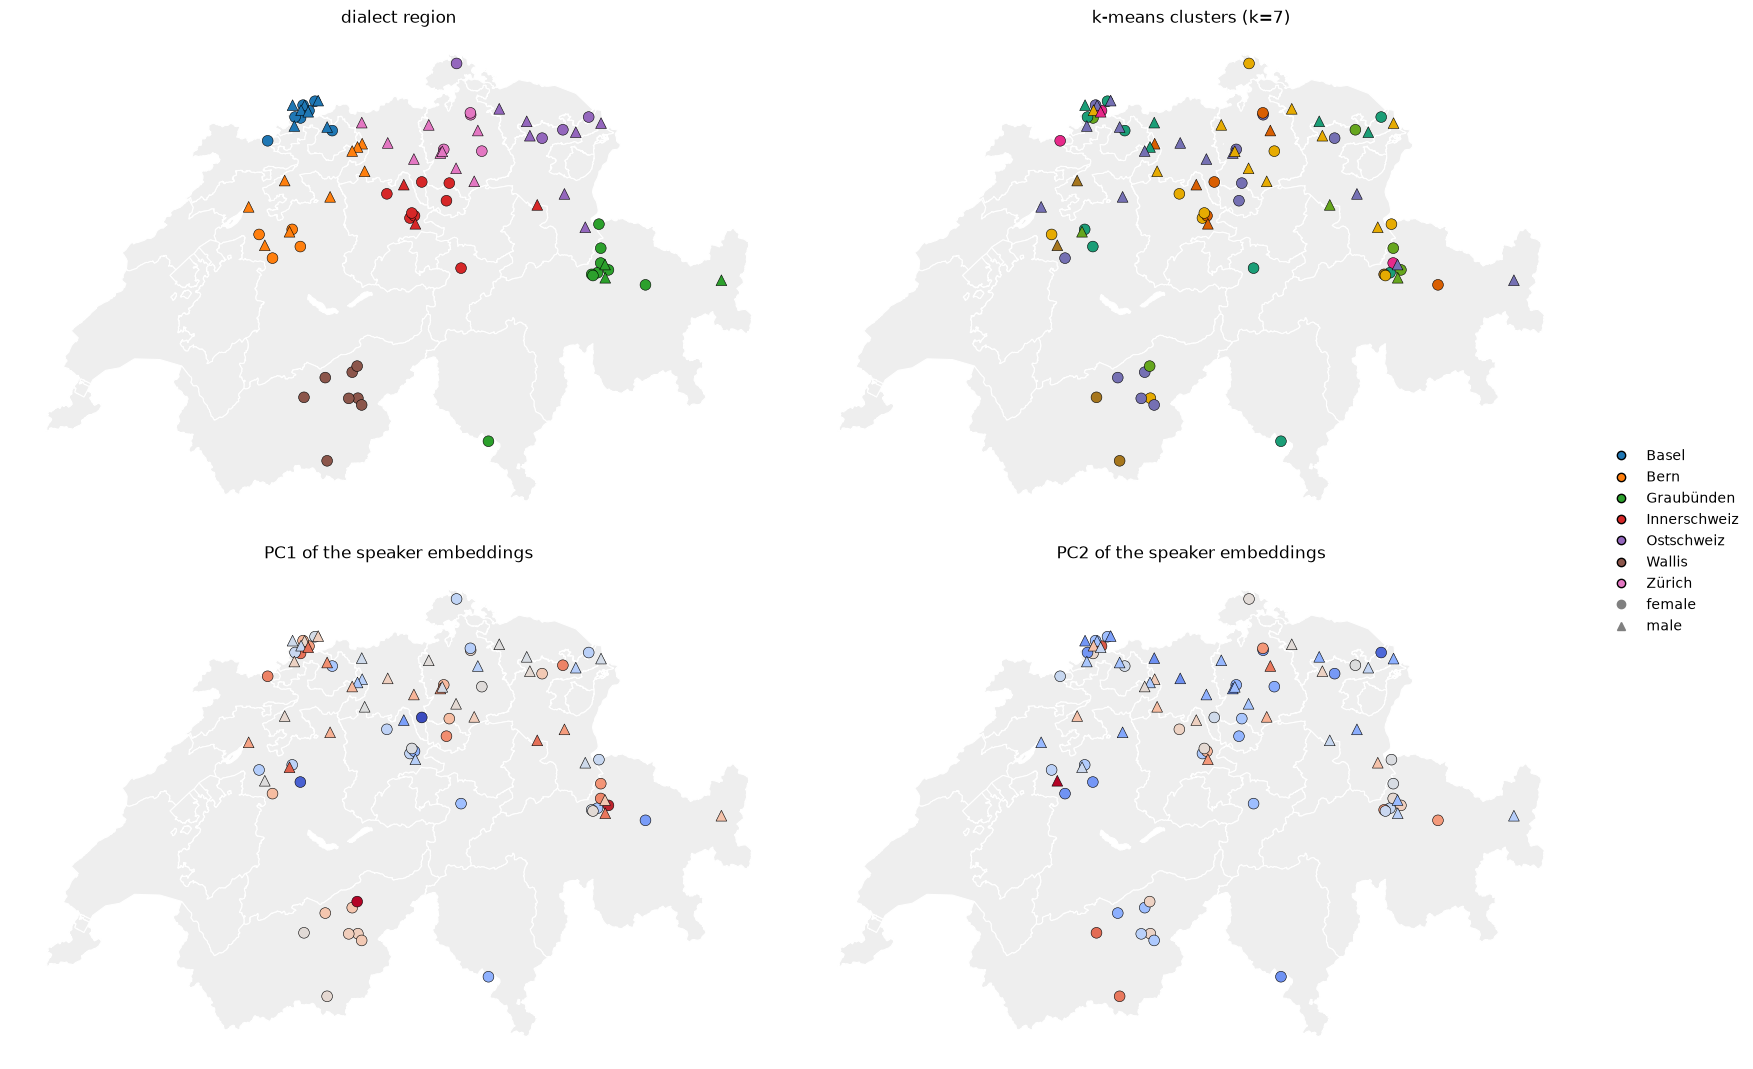

In [12]:
cantons = gpd.read_file(ROOT / "data/geo/cantons.geojson")
located = speakers.E.notna().to_numpy()
jitter = np.random.default_rng(SEED).normal(0, 3000, (len(speakers), 2))
lv95 = speakers[["E", "N"]].to_numpy() + jitter
pcs = PCA(2, random_state=SEED).fit_transform(Z)

panels = [("dialect region", np.array([REGION_COLORS[r] for r in speakers.dialect_region])),
          (f"k-means clusters (k={len(REGIONS)})", plt.get_cmap("Dark2")(k_regions)),
          ("PC1 of the speaker embeddings", plt.get_cmap("coolwarm")(plt.Normalize()(pcs[:, 0]))),
          ("PC2 of the speaker embeddings", plt.get_cmap("coolwarm")(plt.Normalize()(pcs[:, 1])))]
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (title, colors) in zip(axes.flat, panels):
    cantons.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.8)
    plot_speakers(ax, lv95[located], speakers[located], title, colors=colors[located], labels=False)
    ax.set_axis_off()
legend(fig)
fig.tight_layout()
plt.show()

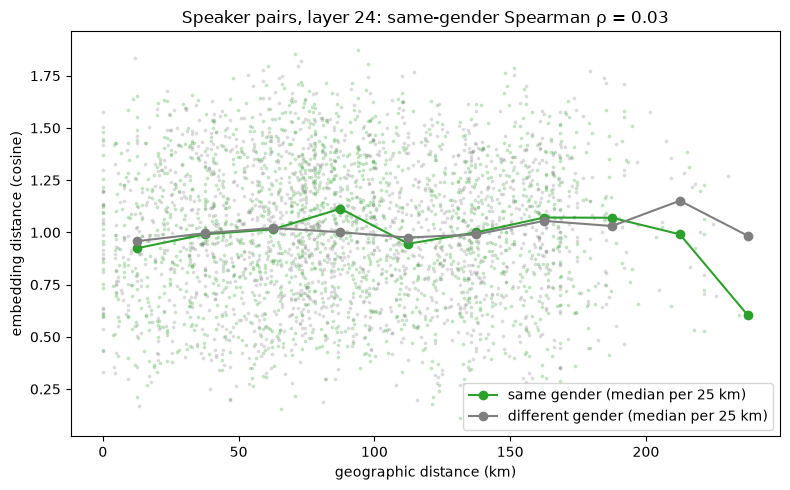

In [13]:
ok = located
D, G = squareform(pdist(Z[ok], "cosine")), squareform(pdist(speakers.loc[ok, ["E", "N"]].to_numpy())) / 1000
i, j = np.triu_indices(ok.sum(), 1)
gender = speakers.gender.to_numpy()[ok]
pairs = pd.DataFrame({"geo_km": G[i, j], "emb": D[i, j], "same_gender": gender[i] == gender[j]})

fig, ax = plt.subplots(figsize=(8, 5))
for same, color in [(True, "tab:green"), (False, "tab:grey")]:
    p = pairs[pairs.same_gender == same]
    ax.scatter(p.geo_km, p.emb, s=3, alpha=0.2, color=color)
    binned = p.groupby(pd.cut(p.geo_km, np.arange(0, 301, 25)), observed=True).emb.median()
    ax.plot([b.mid for b in binned.index], binned, color=color, marker="o",
            label=f"{'same' if same else 'different'} gender (median per 25 km)")
ax.set_xlabel("geographic distance (km)")
ax.set_ylabel("embedding distance (cosine)")
ax.set_title(f"Speaker pairs, layer {LAYER}: same-gender Spearman ρ = {geo_correlation(Z, speakers):.2f}")
ax.legend()
fig.tight_layout()
plt.show()

## Where to go from here

- **More speakers.** Clustering needs many speakers per region: use the tsvs of the whole release (section 1).
- **Other encoders.** Set `MODEL` to a larger Whisper (dialect tends to sit in the middle layers), and compare with
  models trained without text (e.g. XLS-R, HuBERT) or with a speaker-verification model as a "voice only" control:
  dialect structure that the speaker model shows as well is likely voice, not dialect.
- **Remove nuisance directions.** Besides gender: project out directions that predict the speaker's age or the
  recording channel, or use within-speaker variation (clip minus speaker mean) to estimate and remove
  non-dialect directions.
- **Content.** The clips are read sentences; comparing speakers on the *same* sentences (or pooling only over
  words with dialect variants) would isolate pronunciation from content.